# 03 · Signatures — embryonic-development module scores

Score Gast/pSom/Crest per cell with `score_genes` against the shared **union** control pool and read their geography on the manifold. **Gate 2** (non-branching form): a single Gast/pSom-origin → Crest gradient with Crest as the inverse terminal readout (no Gast/pSom hub splitting into two competing arms). Deliverable panels show **RAW** per-cell scores. Deliverable: `signatures.h5ad`, `{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [ ]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{l}: {g.size}/{feat[src].size} genes present')
print('cells:', adata.shape[0], '| scores carried from 01:', [m for m in ['Gast','pSom','Crest'] if m in adata.obs])

Gast: 57/81 genes present
pSom: 60/98 genes present
Crest: 81/104 genes present
cells: 5645 | scores carried from 01: ['Gast', 'pSom', 'Crest']


### Gate 2 — module geography (biology before the GO)
Global module means, smoothed spatial correlations, pseudotime gradients, and a pSom&Crest joint enrichment test (a hub would co-express; an inverse gradient will not).

In [ ]:
print('raw global module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if high)')
pz = (adata.obs['pSom']-adata.obs['pSom'].mean())/adata.obs['pSom'].std()
cz = (adata.obs['Crest']-adata.obs['Crest'].mean())/adata.obs['Crest'].std()
gz = (adata.obs['Gast']-adata.obs['Gast'].mean())/adata.obs['Gast'].std()
joint = ((pz>0.5)&(cz>0.5)).mean(); exp = (pz>0.5).mean()*(cz>0.5).mean()
jgp = ((gz>0.5)&(pz>0.5)).mean(); egp = (gz>0.5).mean()*(pz>0.5).mean()
print(f'joint pSom&Crest-high enrichment = {joint/exp:.2f} (<1 = inverse gradient, not a hub)')
print(f'joint Gast&pSom-high enrichment  = {jgp/egp:.2f} (Gast/pSom overlap at origin)')
print('Gate 2: single Gast/pSom-origin -> Crest gradient, Crest inverse terminal readout -> GO (non-branching)')
print('Gate 3: no bifurcation -> NA')

raw global module means: {'Gast': 0.0117, 'pSom': 0.0062, 'Crest': 0.0092}
smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.16
  Crest_sm vs Gast_sm: r = -0.55
  Crest_sm vs pSom_sm: r = -0.58
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.475
  pSom_sm: rho = +0.107
  Crest_sm: rho = +0.320
Neural-crest-high decile mean pseudotime = 0.58 (terminal if high)
joint pSom&Crest-high enrichment = 0.23 (<1 = inverse gradient, not a hub)
joint Gast&pSom-high enrichment  = 1.00 (Gast/pSom overlap at origin)
Gate 2: single Gast/pSom-origin -> Crest gradient, Crest inverse terminal readout -> GO (non-branching)
Gate 3: no bifurcation -> NA


### Per-module signature figures + colorbars (deliverable, RAW scores)

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


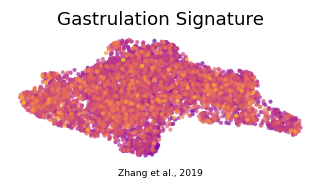

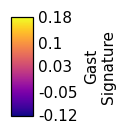

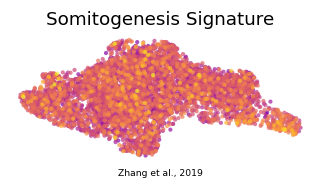

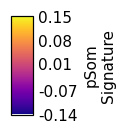

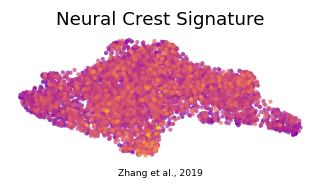

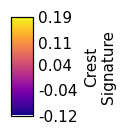

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Zhang et al., 2019', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [ ]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (5645, 14715)
